## Blurry single-brick photos: how many do I have to reshoot?
Sharpness = Laplacian variance inside the brick box (not the whole photo, so the plain table doesn't count). It is divided by the median of the same piece, because a studded brick has more edges than a smooth tile. Nothing is deleted: the blurry photos are only listed in `data/blurry.csv`.

**What this notebook does.** Measures how sharp every photo is inside its brick box, finds the blurry ones, and counts how many photos of each piece must be reshot to reach 100 sharp photos per piece. It also contains a one-off data fix (photos filed under the wrong piece) and a folder audit that looks for folders mixing two different pieces.

**Needs:** `data/boxes.csv`, `dataset/`, `crops224/`, `models/shape_embed.pt`. **Writes:** `data/blur.csv`, `data/blurry.csv`. Nothing is deleted.

Imports. All paths are relative to the repo root.

In [7]:
import os
if os.path.basename(os.getcwd()) == 'notebooks': os.chdir('..')   # all paths below are from the repo root
import csv, glob, cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt

Score every photo: the Laplacian variance (a standard sharpness measure) of the brick crop, divided by that piece's median. The scores are cached in `data/blur.csv`.

In [8]:
# Score every photo once (cached in data/blur.csv; delete that file to redo). Half-size read = fast; boxes are in full-size pixels.
from concurrent.futures import ThreadPoolExecutor
boxes = list(csv.DictReader(open('data/boxes.csv')))

def score(r):
    g = cv2.imread(r['path'], cv2.IMREAD_REDUCED_GRAYSCALE_2)
    if g is None: return None
    x0, y0, x1, y1 = (int(float(r[k]) / 2) for k in ('x0', 'y0', 'x1', 'y1'))
    c = g[max(y0, 0):y1, max(x0, 0):x1]
    if min(c.shape) < 20: return None
    return cv2.Laplacian(cv2.resize(c, (256, 256), interpolation=cv2.INTER_AREA), cv2.CV_64F).var()   # same size for every photo

if not os.path.exists('data/blur.csv'):
    with ThreadPoolExecutor(8) as ex: s = list(ex.map(score, boxes))
    pd.DataFrame({'path': [r['path'] for r in boxes], 'element_id': [r['element_id'] for r in boxes], 'blur': s}).to_csv('data/blur.csv', index=False)
df = pd.read_csv('data/blur.csv', dtype={'element_id': str}).dropna()
n = df.path.str.extract(r'IMG_(\d+)')[0].astype(int)
df.loc[(df.element_id == '4211494') & (n >= 5861), 'element_id'] = '4216248'   # IMG 5861+ in the 4460b gray folder are 2449 (no-op once the data-fix cell below was run)
df['rel'] = df.blur / df.groupby('element_id').blur.transform('median')   # per piece: a smooth tile has fewer edges than a studded brick
print(len(df), 'photos scored |', len(boxes) - len(df), 'skipped (unreadable or tiny box)')

6491 photos scored | 0 skipped (unreadable or tiny box)


**Result:** All 6491 photos were scored and none were skipped. `rel` = 1 means as sharp as a typical photo of the same piece.

Look before choosing a cut-off: a histogram of the relative sharpness, plus 24 crops from the blurriest quarter, ordered worst first.

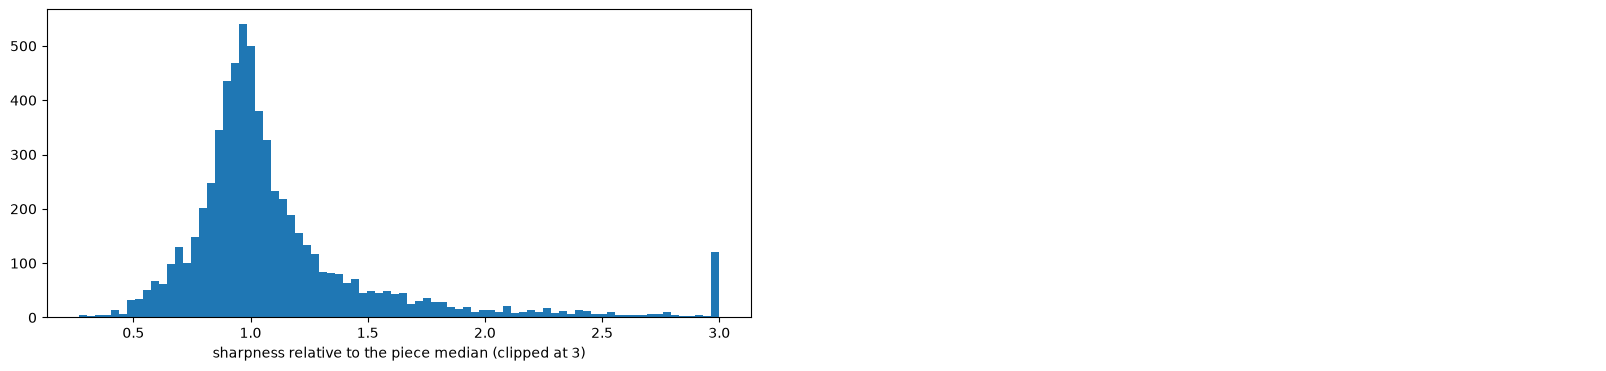

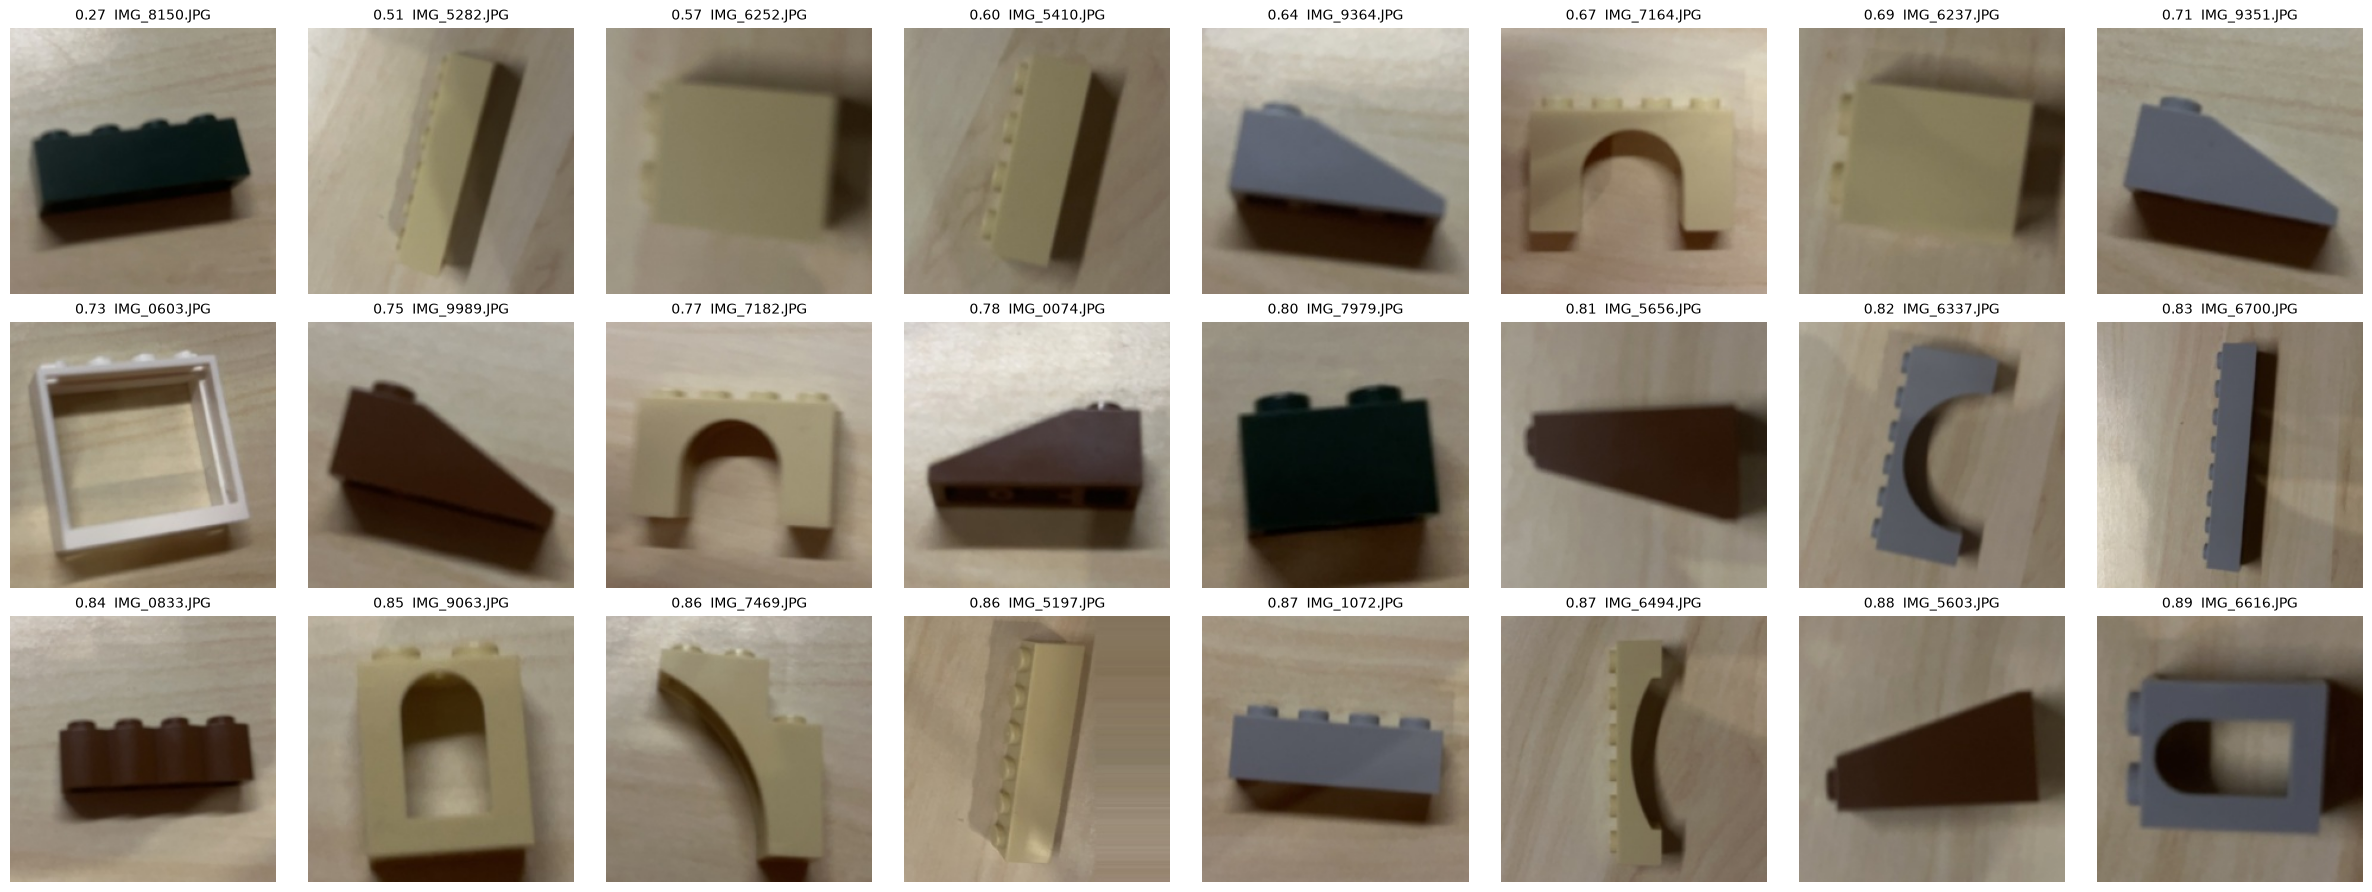

In [9]:
# Look before choosing a cut-off: histogram + 24 crops spread over the blurriest 25% (left = worst). Find where "blurry" starts.
fig, ax = plt.subplots(1, 2, figsize=(20, 4)); ax[0].hist(df.rel.clip(0, 3), bins=80); ax[0].set_xlabel('sharpness relative to the piece median (clipped at 3)'); ax[1].axis('off')
plt.show()
pick = df.sort_values('rel').iloc[np.linspace(0, len(df) * 0.25, 24).astype(int)]
fig, ax = plt.subplots(3, 8, figsize=(24, 9))
for a, (_, r) in zip(ax.flat, pick.iterrows()):
    a.imshow(cv2.cvtColor(cv2.imread('crops224/' + r.path), cv2.COLOR_BGR2RGB)); a.axis('off'); a.set_title(f'{r.rel:.2f}  {os.path.basename(r.path)}', fontsize=10)
plt.tight_layout(); plt.show()

**Result:** Use the montage to see where the photos stop looking blurry. That value becomes `THRESH` in the next cell.

Apply the cut-off and count, per piece, how many sharp photos there are and how many are missing to reach `TARGET`.

In [10]:
# Pick the cut-off by eye from the montage above, then read how many photos each piece keeps and how many to reshoot.
# Pieces with no photo at all (incl. the 4460b/2449 mix-up: photos of 4211494 are really 4216248) show up with reshoot = TARGET.
THRESH, TARGET = 0.5, 100   # rel < THRESH = blurry | sharp photos wanted per piece (gallery needs ~20-60, training more)
df['sharp'] = df.rel >= THRESH
em = {r['element_id']: r for r in csv.DictReader(open('data/element_map.csv'))}
t = pd.DataFrame(index=list(em)).join(df.groupby('element_id').agg(photos=('rel', 'size'), sharp=('sharp', 'sum'))).fillna(0).astype(int)
t['reshoot'] = (TARGET - t.sharp).clip(lower=0)
t.insert(0, 'piece', [f"{em[e]['part_num']} {em[e]['color']}" for e in t.index])
print(t.sort_values('reshoot', ascending=False).to_string())
print(f'\nblurry: {(~df.sharp).sum()} of {len(df)} photos | pieces needing a reshoot: {(t.reshoot > 0).sum()} of {len(t)} | photos to shoot in total: {t.reshoot.sum()}')
df[~df.sharp][['path', 'element_id', 'rel']].to_csv('data/blurry.csv', index=False)

                                piece  photos  sharp  reshoot
4211414       3069b Light Bluish Gray       0      0      100
4558169       63864 Light Bluish Gray       0      0      100
6092559  6178pr0002 Light Bluish Gray       0      0      100
4645397        4490 Light Bluish Gray      71     71       29
4521915               3005 Dark Green     101     88       12
4211393        3009 Light Bluish Gray      88     88       12
6106189       15254 Light Bluish Gray      93     93        7
4211181           30137 Reddish Brown     105     93        7
6031057                      6182 Tan      93     93        7
6066113                   15332 Black      97     96        4
4618876                     92950 Tan      99     99        1
4109995                      3004 Tan      99     99        1
4245571               3010 Dark Green     119     99        1
4642933                     90195 Tan     113    113        0
6063943                     87552 Tan     248    248        0
4121972 

**Result:** Three pieces have no photos at all (3069b, 63864, 6178pr0002) and need a full 100. Of the photographed pieces, only 4490 is far short (29). The blurry photo list is saved to `data/blurry.csv`.

One-off data fix: photos IMG 5861-6020 were filed as 4460b but show 2449. This moves them and rewrites every label file. It is safe to re-run.

In [11]:
# DATA FIX (run once, safe to re-run): IMG 5861-6020 sit in dataset/4460b_194_4211494/ but are 2449 gray (element 4216248).
# Moves them to dataset/2449_194_4216248/ (and crops224/ the same), then rewrites the paths + element/part in labels.csv, boxes.csv, blur.csv and the gallery.
# dataset/ only holds hardlinks, so the original photos are never touched.
import re
em = {r['element_id']: r for r in csv.DictReader(open('data/element_map.csv'))}
OLD, NEW = '4460b_194_4211494', '2449_194_4216248'
num = lambda s: s.str.extract(r'IMG_(\d+)')[0].astype(float)
hit = lambda d: d.path.str.contains(OLD) & (num(d.path) >= 5861)
lab = pd.read_csv('data/labels.csv', dtype=str, keep_default_na=False)
moved = 0
for p in lab.path[hit(lab)]:
    for base in ('', 'crops224/'):
        if os.path.exists(base + p):
            os.makedirs(os.path.dirname(base + p.replace(OLD, NEW)), exist_ok=True); os.rename(base + p, base + p.replace(OLD, NEW)); moved += 1
print(moved, 'files moved (photos + crops) into', NEW)
for f in ('data/labels.csv', 'data/boxes.csv', 'data/blur.csv'):
    if not os.path.exists(f): continue
    d = pd.read_csv(f, dtype=str, keep_default_na=False); m = hit(d)
    d.loc[m, 'path'] = d.path[m].str.replace(OLD, NEW); d.loc[m, 'element_id'] = '4216248'
    if 'part_num' in d: d.loc[m, ['part_num', 'part_name']] = [em['4216248']['part_num'], em['4216248']['part_name']]
    d.to_csv(f, index=False); print(f, ':', m.sum(), 'rows relabeled')
g = dict(np.load('data/gallery.npz'))
gn = np.array([int(re.search(r'IMG_(\d+)', s).group(1)) if re.search(r'IMG_(\d+)', s) else -1 for s in g['src']])
m = (g['color'] == '194') & (gn >= 5861) & np.isin(g['shape'], ['4460b', '2449'])
g['shape'] = g['shape'].astype('<U12'); g['shape'][m] = '2449'
g['src'] = np.array([s.replace(OLD, NEW) if k else s for s, k in zip(g['src'], m)])
np.savez_compressed('data/gallery.npz', **g); print('data/gallery.npz :', m.sum(), 'entries relabeled')

0 files moved (photos + crops) into 2449_194_4216248
data/labels.csv : 0 rows relabeled
data/boxes.csv : 0 rows relabeled
data/blur.csv : 0 rows relabeled
data/gallery.npz : 6 entries relabeled


**Result:** The saved run moved 0 files, because the fix had already been applied. Only the gallery still needed 6 entries relabelled.

Folder audit: fingerprint every photo in a folder, split the folder into two clusters, and rank folders by how different the clusters are. A folder with two clean blocks of IMG numbers probably holds two different pieces.

1 of 6492 photos have no crop in crops224/ (skipped): ['dataset/3009_5_4112982/IMG_5204.JPG']
dataset/3040b_192_4211199                   225 photos | cluster distance 0.197 | smaller cluster  10: IMG 9863-9863 9911-9919
dataset/3040b_141_4255624                   212 photos | cluster distance 0.166 | smaller cluster   1: IMG 121-121
dataset/2449_194_4216248                    159 photos | cluster distance 0.147 | smaller cluster   5: IMG 5927-5931
dataset/90195_194_4642934                   154 photos | cluster distance 0.069 | smaller cluster   8: IMG 6558-6565
dataset/3062b_192_4211183                   105 photos | cluster distance 0.055 | smaller cluster  35: IMG 1377-1377 1387-1410 1434-1447
dataset/15332_26_6066113                     97 photos | cluster distance 0.052 | smaller cluster  20: IMG 6117-6126 6171-6180
dataset/15254_194_6106189                    93 photos | cluster distance 0.051 | smaller cluster   1: IMG 6363-6363
dataset/6182_5_6031057                       93 p

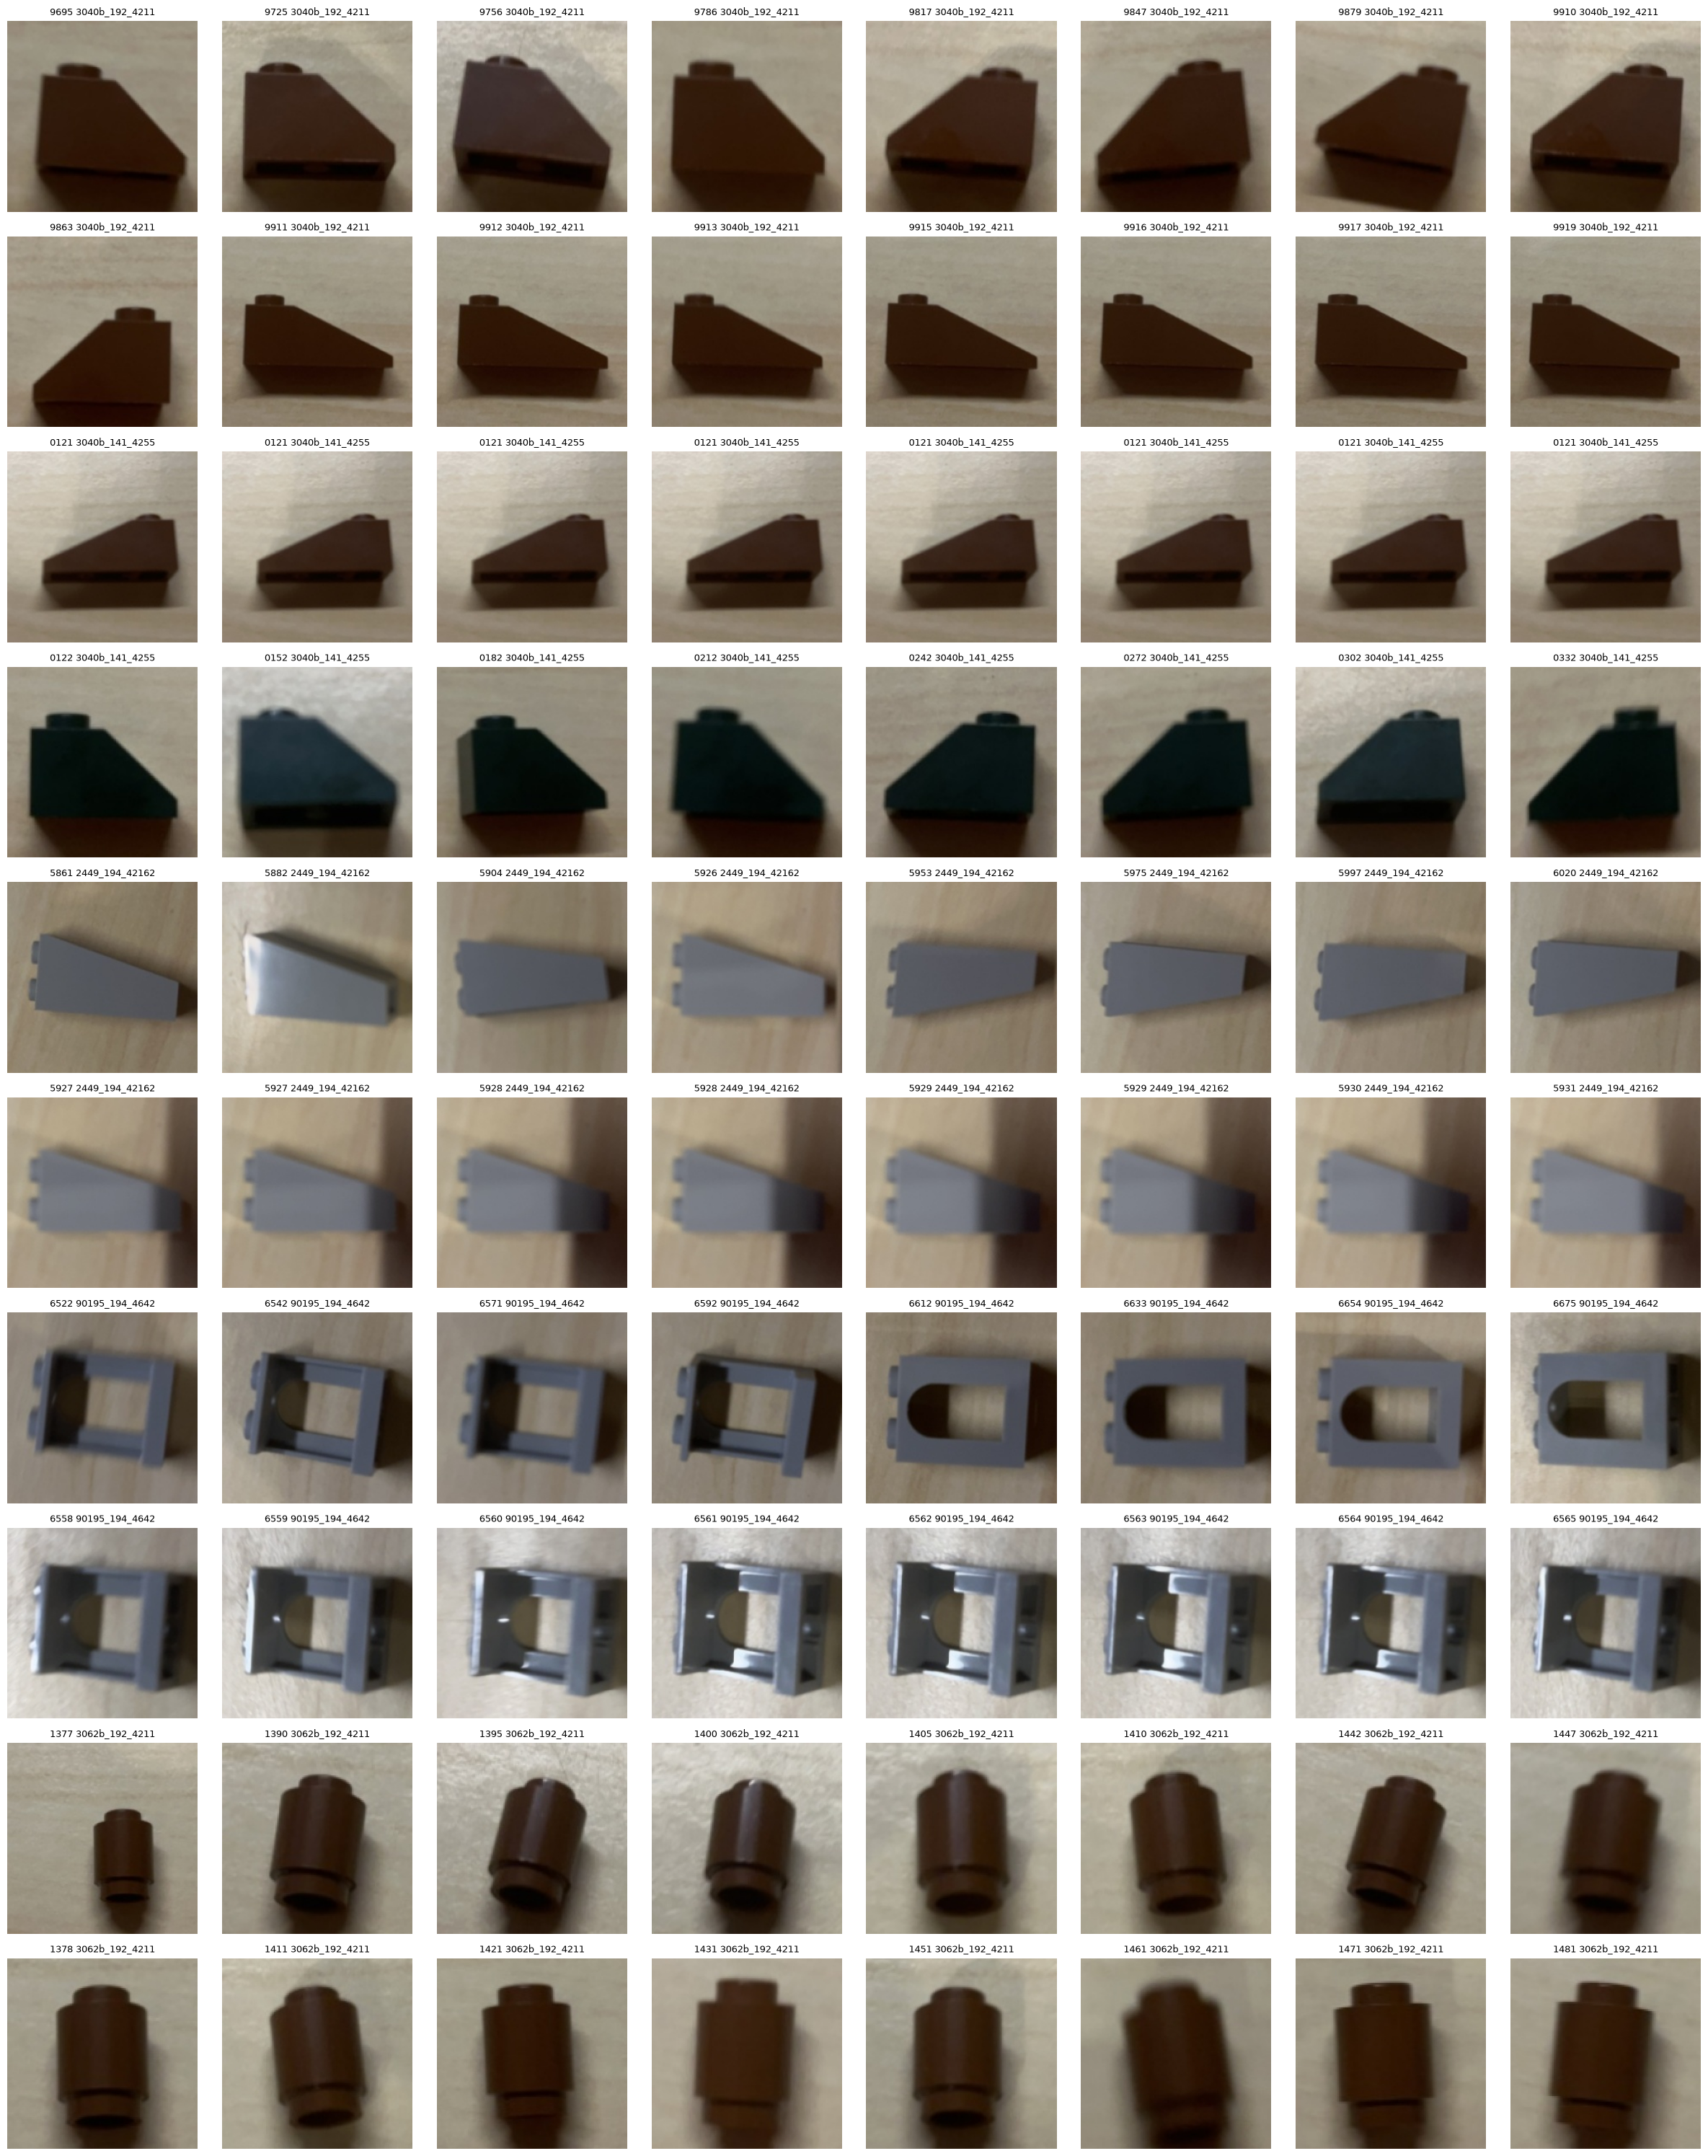

In [12]:
# FOLDER AUDIT: does every folder hold ONE piece? Fingerprint each photo, split the folder in 2 clusters (2-means), rank folders by how far apart
# the clusters are, print each small cluster's IMG numbers, show both clusters. Two pieces shot in a row = two clean IMG blocks (like 4460b/2449).
# Shape only (the fingerprint is color-blind), so a wrong color folder will not show here. Run after the data-fix cell.
import sys; sys.path.insert(0, '.'); import lego_lookup as L
emb = L.load_embedder()
lab = pd.read_csv('data/labels.csv', dtype=str); lab['n'] = lab.path.str.extract(r'IMG_(\d+)')[0].astype(int)
have = lab.path.map(lambda p: os.path.exists('crops224/' + p))
print(len(lab) - have.sum(), 'of', len(lab), 'photos have no crop in crops224/ (skipped):', list(lab.path[~have][:5]))
lab = lab[have]
res = []
for folder, d in lab.groupby(lab.path.str.rsplit('/', n=1).str[0]):   # lab.path folders: dataset/<part>_<color>_<element>
    d = d.sort_values('n'); v = L.embed(emb, [cv2.cvtColor(cv2.imread('crops224/' + p), cv2.COLOR_BGR2RGB) for p in d.path])
    c = v[[0, (v @ v[0]).argmin()]]   # start from the first photo and the photo least like it
    for _ in range(10):
        a = (v @ c.T).argmax(1)
        c = np.stack([v[a == k].mean(0) if (a == k).any() else c[k] for k in (0, 1)]); c /= np.linalg.norm(c, axis=1, keepdims=True)
    k = int((a == 1).sum() < (a == 0).sum())   # k = the smaller cluster
    ns = d.n.values[a == k]; blocks = np.split(ns, np.where(np.diff(ns) > 5)[0] + 1) if len(ns) else []
    res.append(dict(folder=folder, photos=len(d), dist=1 - float(c[0] @ c[1]), small=len(ns), blocks=' '.join(f'{b[0]}-{b[-1]}' for b in blocks[:6]), d=d, a=a))
res.sort(key=lambda r: -r['dist'])
for r in res[:12]: print(f"{r['folder']:42s} {r['photos']:4d} photos | cluster distance {r['dist']:.3f} | smaller cluster {r['small']:3d}: IMG {r['blocks']}")
fig, ax = plt.subplots(10, 8, figsize=(24, 30))
for a_ in ax.flat: a_.axis('off')
for i, r in enumerate(res[:5]):
    for k in (0, 1):
        ps = r['d'].path.values[r['a'] == k]
        for j, p in enumerate(ps[np.linspace(0, len(ps) - 1, 8).astype(int)] if len(ps) else []):
            x = ax[2 * i + k, j]; x.imshow(cv2.cvtColor(cv2.imread('crops224/' + p), cv2.COLOR_BGR2RGB)); x.set_title(f"{os.path.basename(p)[4:8]} {r['folder'].split('/')[1][:14]}", fontsize=9)
plt.tight_layout(); plt.show()

**Result:** The top folders show which IMG ranges to check by eye. A high distance with a tiny cluster (one or two photos) is usually just an odd angle, not a second piece.

Shut the kernel down, so GPU and RAM are freed after Run All.

In [ ]:
get_ipython().kernel.do_shutdown(False)   # last cell: kills this kernel so GPU/RAM is freed after Run All

## Conclusion
Blur is not a big problem in this dataset: almost every piece already has close to 100 sharp photos. What needs reshooting are the three pieces with no photos (3069b, 63864, 6178pr0002) and a top-up for 4490. The 4460b/2449 mix-up has been fixed in every label file, and the folder audit gives a short list of IMG ranges to check by hand.